In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
orders=pd.read_csv("/content/orders.csv")
products=pd.read_csv("/content/products.csv")
order_items=pd.read_csv("/content/order_items.csv")
refund_orderitems=pd.read_csv("/content/order_item_refunds.csv")

In [ ]:
web_sessions=pd.read_csv("/content/website_sessions.csv")
web_pageviews=pd.read_csv("/content/website_pageviews.csv")

website_sessions
       │
       ├── website_pageviews
       │
       └── orders
              │
              └── order_items
                       │
                       ├── products
                       │
                       └── order_item_refunds

**website sessions Data Cleaning**

In [ ]:
web_sessions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 472871 entries, 0 to 472870
Data columns (total 9 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   website_session_id  472871 non-null  int64 
 1   created_at          472871 non-null  object
 2   user_id             472871 non-null  int64 
 3   is_repeat_session   472871 non-null  int64 
 4   utm_source          389543 non-null  object
 5   utm_campaign        389543 non-null  object
 6   utm_content         389543 non-null  object
 7   device_type         472871 non-null  object
 8   http_referer        432954 non-null  object
dtypes: int64(3), object(6)
memory usage: 32.5+ MB


In [ ]:
web_sessions.isnull().sum()

,0
website_session_id,0
created_at,0
user_id,0
is_repeat_session,0
utm_source,83328
utm_campaign,83328
utm_content,83328
device_type,0
http_referer,39917


In [ ]:
web_sessions.duplicated().sum()

np.int64(0)

In [ ]:
(web_sessions.isnull().sum() / len(web_sessions) * 100).round(2)

,0
website_session_id,0.00
created_at,0.00
user_id,0.00
is_repeat_session,0.00
utm_source,17.62
utm_campaign,17.62
utm_content,17.62
device_type,0.00
http_referer,8.44


In [ ]:
web_sessions[web_sessions['utm_source'].isna()][
    ['utm_source', 'utm_campaign', 'utm_content']
].isna().all(axis=1).value_counts()

,count
True,83328


In [ ]:
web_sessions[web_sessions['utm_source'].isna()]['http_referer'].isna().value_counts()

,count
http_referer,
False,43411
True,39917


In [ ]:
web_sessions[web_sessions['utm_source'].isna()]['http_referer'].value_counts().head(20)

,count
http_referer,
https://www.gsearch.com,35202
https://www.bsearch.com,8209


In [ ]:
web_sessions.duplicated().sum()

np.int64(0)

In [ ]:
web_sessions['website_session_id'].duplicated().sum()

np.int64(0)

In [ ]:
web_sessions.dtypes

,0
website_session_id,int64
created_at,object
user_id,int64
is_repeat_session,int64
utm_source,object
utm_campaign,object
utm_content,object
device_type,object
http_referer,object


In [ ]:
web_sessions['created_at'] = pd.to_datetime(web_sessions['created_at'])

In [ ]:
web_sessions.dtypes

,0
website_session_id,int64
created_at,datetime64[ns]
user_id,int64
is_repeat_session,int64
utm_source,object
utm_campaign,object
utm_content,object
device_type,object
http_referer,object


In [ ]:
web_sessions['is_repeat_session'].value_counts()

,count
is_repeat_session,
0,394318
1,78553


In [ ]:
web_sessions['device_type'].value_counts()

,count
device_type,
desktop,327027
mobile,145844


In [ ]:
web_sessions['utm_source'].value_counts(dropna=False)

,count
utm_source,
gsearch,316035
NaN,83328
bsearch,62823
socialbook,10685


In [ ]:
web_sessions['utm_source'] = web_sessions['utm_source'].fillna('Unattributed')

In [ ]:
web_sessions['utm_source'].value_counts(dropna=False)

,count
utm_source,
gsearch,316035
Unattributed,83328
bsearch,62823
socialbook,10685


**WebPageviews Data Cleaning**

In [ ]:
def inspect_data(df,name):
    print(f"\n{'='*50}")
    print(f"TABLE: {name}")
    print(f"{'='*50}")

    print("\nShape:")
    print(df.shape)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())


inspect_data(web_pageviews, "website_pageviews")



TABLE: website_pageviews

Shape:
(1188124, 4)

Data Types:
website_pageview_id     int64
created_at             object
website_session_id      int64
pageview_url           object
dtype: object

Missing Values:
website_pageview_id    0
created_at             0
website_session_id     0
pageview_url           0
dtype: int64

Duplicate Rows:
0


In [ ]:
web_pageviews.duplicated().sum()

np.int64(0)

In [ ]:
web_pageviews.dtypes

,0
website_pageview_id,int64
created_at,object
website_session_id,int64
pageview_url,object


In [ ]:
web_pageviews['created_at'] = pd.to_datetime(web_pageviews['created_at'])

In [ ]:
web_pageviews.dtypes

,0
website_pageview_id,int64
created_at,datetime64[ns]
website_session_id,int64
pageview_url,object


**Orders Data Cleaning**

In [ ]:
inspect_data(orders, "orders")


TABLE: orders

Shape:
(32313, 8)

Data Types:
order_id                int64
created_at             object
website_session_id      int64
user_id                 int64
primary_product_id      int64
items_purchased         int64
price_usd             float64
cogs_usd              float64
dtype: object

Missing Values:
order_id              0
created_at            0
website_session_id    0
user_id               0
primary_product_id    0
items_purchased       0
price_usd             0
cogs_usd              0
dtype: int64

Duplicate Rows:
0


In [ ]:
orders['created_at'] = pd.to_datetime(orders['created_at'])

In [ ]:
orders.dtypes

,0
order_id,int64
created_at,datetime64[ns]
website_session_id,int64
user_id,int64
primary_product_id,int64
items_purchased,int64
price_usd,float64
cogs_usd,float64


In [ ]:
orders.duplicated().sum()

np.int64(0)

**Orders Items Data Cleaning**

In [ ]:
inspect_data(order_items, "order_items")


TABLE: order_items

Shape:
(40025, 7)

Data Types:
order_item_id        int64
created_at          object
order_id             int64
product_id           int64
is_primary_item      int64
price_usd          float64
cogs_usd           float64
dtype: object

Missing Values:
order_item_id      0
created_at         0
order_id           0
product_id         0
is_primary_item    0
price_usd          0
cogs_usd           0
dtype: int64

Duplicate Rows:
0


In [ ]:
order_items['created_at'] = pd.to_datetime(order_items['created_at'])

In [ ]:
order_items.dtypes

,0
order_item_id,int64
created_at,datetime64[ns]
order_id,int64
product_id,int64
is_primary_item,int64
price_usd,float64
cogs_usd,float64


**products Data Cleaning**

In [ ]:
inspect_data(products, "products")


TABLE: products

Shape:
(4, 3)

Data Types:
product_id       int64
created_at      object
product_name    object
dtype: object

Missing Values:
product_id      0
created_at      0
product_name    0
dtype: int64

Duplicate Rows:
0


In [ ]:
products['created_at'] = pd.to_datetime(products['created_at'])

In [ ]:
products.dtypes

,0
product_id,int64
created_at,datetime64[ns]
product_name,object


**Refund order Items data cleaning**

In [ ]:
inspect_data(refund_orderitems, "order_item_refunds")


TABLE: order_item_refunds

Shape:
(1731, 5)

Data Types:
order_item_refund_id      int64
created_at               object
order_item_id             int64
order_id                  int64
refund_amount_usd       float64
dtype: object

Missing Values:
order_item_refund_id    0
created_at              0
order_item_id           0
order_id                0
refund_amount_usd       0
dtype: int64

Duplicate Rows:
0


In [ ]:
refund_orderitems['created_at'] = pd.to_datetime(refund_orderitems['created_at'])

In [ ]:
refund_orderitems.dtypes

,0
order_item_refund_id,int64
created_at,datetime64[ns]
order_item_id,int64
order_id,int64
refund_amount_usd,float64


**Detecting Outliers For All tables**

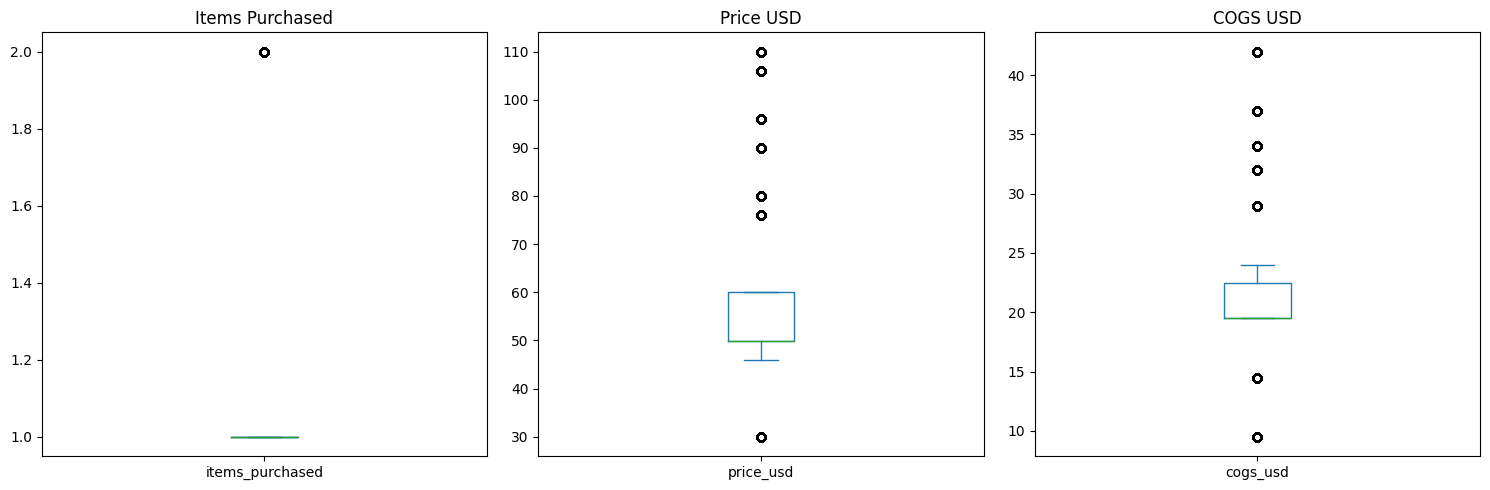

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

orders['items_purchased'].plot(kind='box', ax=axes[0])
axes[0].set_title('Items Purchased')

orders['price_usd'].plot(kind='box', ax=axes[1])
axes[1].set_title('Price USD')

orders['cogs_usd'].plot(kind='box', ax=axes[2])
axes[2].set_title('COGS USD')

plt.tight_layout()
plt.show()

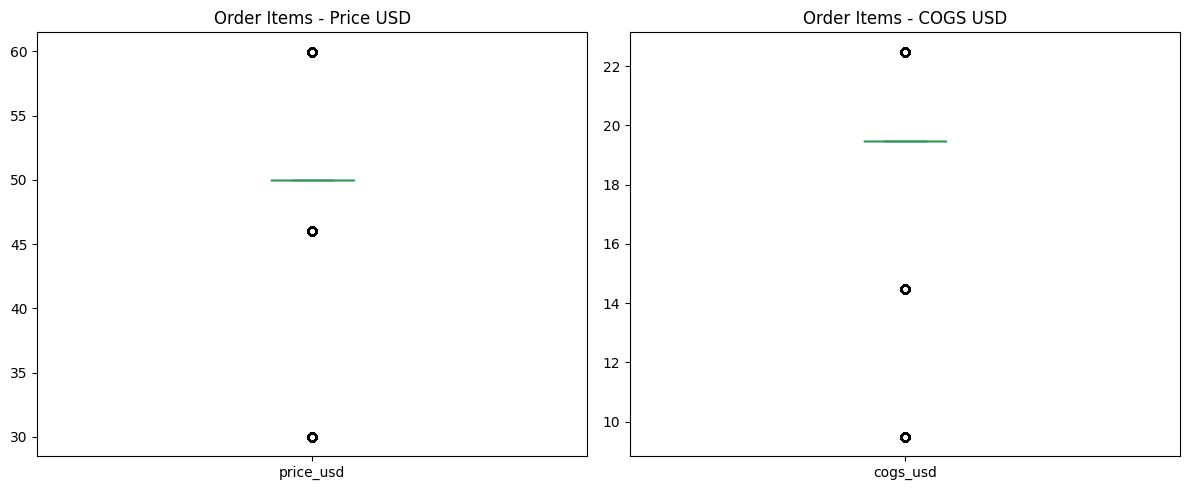

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

order_items['price_usd'].plot(kind='box', ax=axes[0])
axes[0].set_title('Order Items - Price USD')

order_items['cogs_usd'].plot(kind='box', ax=axes[1])
axes[1].set_title('Order Items - COGS USD')

plt.tight_layout()
plt.show()

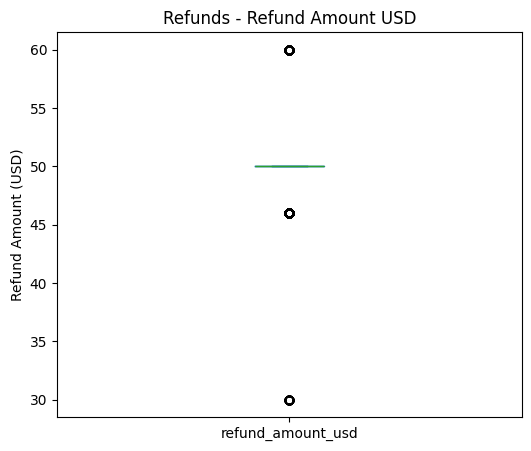

In [ ]:
refund_orderitems['refund_amount_usd'].plot(kind='box', figsize=(6, 5))

plt.title('Refunds - Refund Amount USD')
plt.ylabel('Refund Amount (USD)')

plt.show()

In [ ]:
# Export all cleaned tables as CSV files

cleaned_tables = {
    'website_sessions': web_sessions,
    'website_pageviews': web_pageviews,
    'orders': orders,
    'order_items': order_items,
    'order_item_refunds': refund_orderitems,
    'products': products
}

for name, df in cleaned_tables.items():
    df.to_csv(f'{name}_clean.csv', index=False)

print("All 6 cleaned CSV files have been created successfully.")

All 6 cleaned CSV files have been created successfully.


In [ ]:
import os

for name in cleaned_tables:
    file_name = f'{name}_clean.csv'
    print(file_name, "→", os.path.getsize(file_name), "bytes")

website_sessions_clean.csv → 41474192 bytes
website_pageviews_clean.csv → 54539150 bytes
orders_clean.csv → 1787224 bytes
order_items_clean.csv → 1893888 bytes
order_item_refunds_clean.csv → 72233 bytes
products_clean.csv → 220 bytes


In [ ]:
from google.colab import files

files.download('website_sessions_clean.csv')
files.download('website_pageviews_clean.csv')
files.download('orders_clean.csv')
files.download('order_items_clean.csv')
files.download('order_item_refunds_clean.csv')
files.download('products_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>